In [2]:
!pip -q install xgboost plotly scikit-learn

#DASHBOARD
## STEP1

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from IPython.display import display, Markdown
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from xgboost import XGBRegressor

df = pd.read_csv("/content/5g_network_traffic_qos_starter.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values(["cell_id", "timestamp"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Base stations:", df["cell_id"].nunique())
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
display(df.head())

Dataset shape: (504, 11)
Base stations: 3
Time range: 2026-01-01 00:00:00 to 2026-01-07 23:00:00


,timestamp,cell_id,traffic_volume_gb,active_connections,throughput_mbps,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_label,anomaly_type,data_source
0,2026-01-01 00:00:00,GNB_001,12.158,331,27.667,25.72,0.371,17.03,0,normal,synthetic_demo_not_real_network_data
1,2026-01-01 01:00:00,GNB_001,9.753,303,22.193,21.44,0.266,19.29,0,normal,synthetic_demo_not_real_network_data
2,2026-01-01 02:00:00,GNB_001,13.043,432,29.681,24.07,0.397,21.28,0,normal,synthetic_demo_not_real_network_data
3,2026-01-01 03:00:00,GNB_001,10.493,300,23.879,19.85,0.346,20.65,0,normal,synthetic_demo_not_real_network_data
4,2026-01-01 04:00:00,GNB_001,11.661,306,26.535,26.92,0.278,19.83,0,normal,synthetic_demo_not_real_network_data


In [4]:
print("Missing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("Duplicate rows:", df.duplicated().sum())
print("Data types:")
display(df.dtypes.to_frame("data_type"))

print("Summary statistics:")
display(df.describe().round(2))

Missing values:


,missing_count
timestamp,0
cell_id,0
traffic_volume_gb,0
active_connections,0
throughput_mbps,0
latency_ms,0
packet_loss_rate_pct,0
sinr_db,0
anomaly_label,0
anomaly_type,0


Duplicate rows: 0
Data types:


,data_type
timestamp,datetime64[ns]
cell_id,object
traffic_volume_gb,float64
active_connections,int64
throughput_mbps,float64
latency_ms,float64
packet_loss_rate_pct,float64
sinr_db,float64
anomaly_label,int64
anomaly_type,object


Summary statistics:


,timestamp,traffic_volume_gb,active_connections,throughput_mbps,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_label
count,504,504.00,504.00,504.00,504.00,504.00,504.00,504.00
mean,2026-01-04 11:30:00,15.44,429.99,35.15,25.07,0.34,20.00,0.01
min,2026-01-01 00:00:00,3.26,106.00,7.41,10.49,0.03,7.71,0.00
25%,2026-01-02 17:45:00,11.63,315.00,26.46,22.18,0.26,18.77,0.00
50%,2026-01-04 11:30:00,14.61,412.00,33.25,24.72,0.33,20.04,0.00
75%,2026-01-06 05:15:00,18.78,518.25,42.73,27.32,0.40,21.25,0.00
max,2026-01-07 23:00:00,29.88,909.00,68.00,108.09,3.55,25.73,1.00
std,NaN,5.07,153.64,11.54,5.94,0.18,1.97,0.08


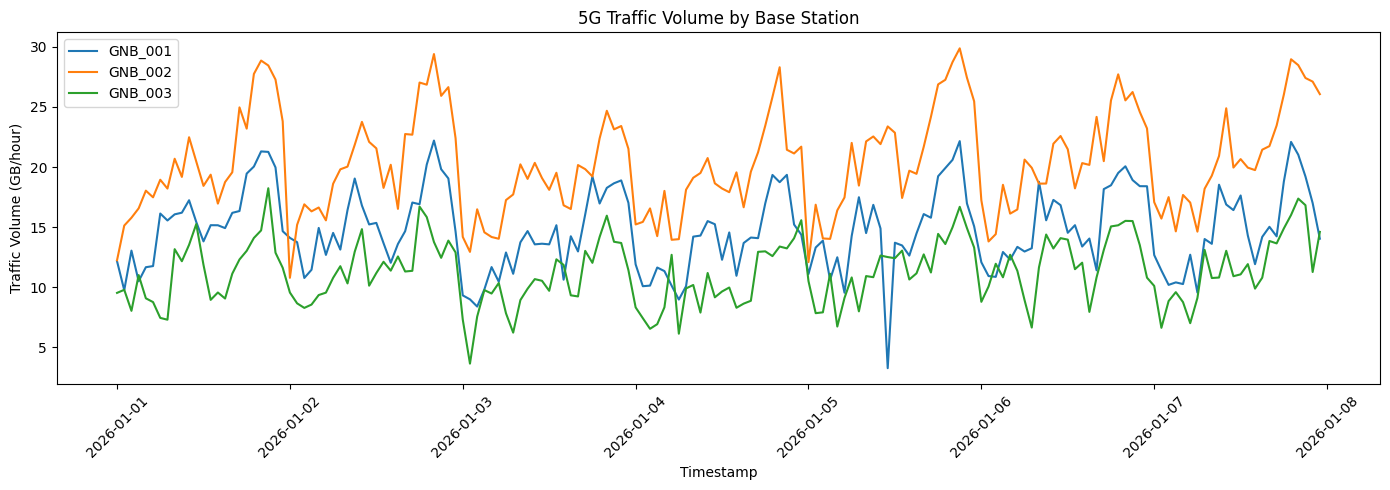

In [5]:
plt.figure(figsize=(14, 5))

for cell, group in df.groupby("cell_id"):
    plt.plot(
        group["timestamp"],
        group["traffic_volume_gb"],
        label=cell
    )

plt.title("5G Traffic Volume by Base Station")
plt.xlabel("Timestamp")
plt.ylabel("Traffic Volume (GB/hour)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

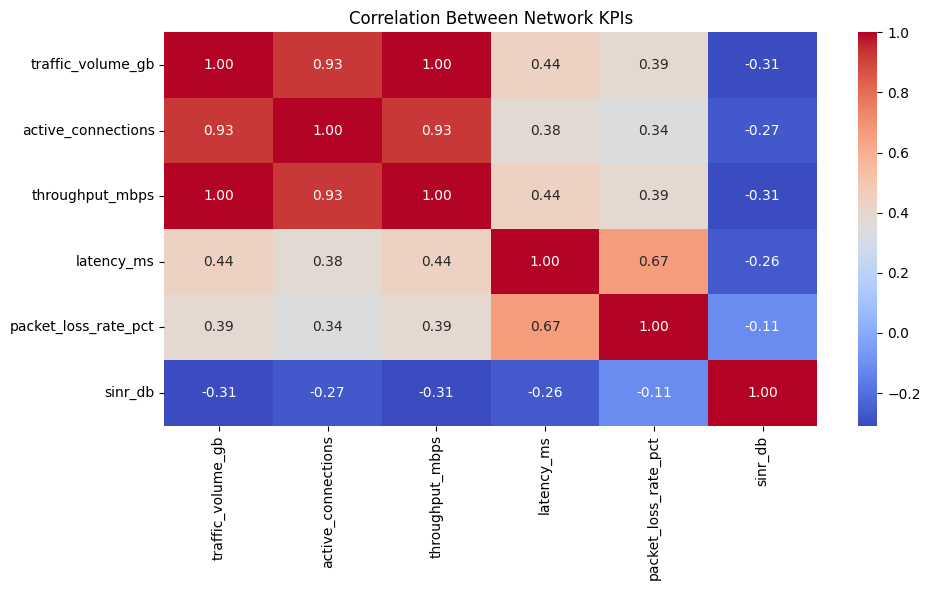

In [6]:
metrics = [
    "traffic_volume_gb",
    "active_connections",
    "throughput_mbps",
    "latency_ms",
    "packet_loss_rate_pct",
    "sinr_db"
]

plt.figure(figsize=(10, 6))
sns.heatmap(
    df[metrics].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Network KPIs")
plt.tight_layout()
plt.show()

In [7]:
summary = df.groupby("cell_id").agg(
    avg_traffic_gb=("traffic_volume_gb", "mean"),
    peak_traffic_gb=("traffic_volume_gb", "max"),
    avg_latency_ms=("latency_ms", "mean"),
    avg_packet_loss_pct=("packet_loss_rate_pct", "mean"),
    avg_sinr_db=("sinr_db", "mean"),
    known_anomalies=("anomaly_label", "sum")
).round(2)

display(summary)

,avg_traffic_gb,peak_traffic_gb,avg_latency_ms,avg_packet_loss_pct,avg_sinr_db,known_anomalies
cell_id,,,,,,
GNB_001,14.75,22.20,24.43,0.33,19.91,1
GNB_002,20.31,29.88,27.69,0.41,19.46,1
GNB_003,11.27,18.24,23.09,0.28,20.63,1


In [8]:
df = df.sort_values(["cell_id", "timestamp"]).copy()

df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

g = df.groupby("cell_id")["traffic_volume_gb"]

for lag in [1, 2, 3, 24]:
    df[f"traffic_lag_{lag}"] = g.shift(lag)

df["rolling_mean_6h"] = g.transform(
    lambda s: s.shift(1).rolling(6).mean()
)
df["rolling_mean_24h"] = g.transform(
    lambda s: s.shift(1).rolling(24).mean()
)

display(df[[
    "timestamp", "cell_id", "traffic_volume_gb",
    "traffic_lag_1", "traffic_lag_24", "rolling_mean_24h"
]].tail(10))

,timestamp,cell_id,traffic_volume_gb,traffic_lag_1,traffic_lag_24,rolling_mean_24h
494,2026-01-07 14:00:00,GNB_003,9.879,11.918,12.038,11.292333
495,2026-01-07 15:00:00,GNB_003,10.790,9.879,7.940,11.202375
496,2026-01-07 16:00:00,GNB_003,13.844,10.790,10.823,11.321125
497,2026-01-07 17:00:00,GNB_003,13.644,13.844,13.097,11.447000
498,2026-01-07 18:00:00,GNB_003,14.888,13.644,15.056,11.469792
499,2026-01-07 19:00:00,GNB_003,16.007,14.888,15.152,11.462792
500,2026-01-07 20:00:00,GNB_003,17.373,16.007,15.519,11.498417
501,2026-01-07 21:00:00,GNB_003,16.825,17.373,15.504,11.575667
502,2026-01-07 22:00:00,GNB_003,11.263,16.825,13.503,11.630708
503,2026-01-07 23:00:00,GNB_003,14.601,11.263,10.789,11.537375


24-hour-ahead MAE: 1.762 GB/hour
24-hour-ahead RMSE: 2.229 GB/hour


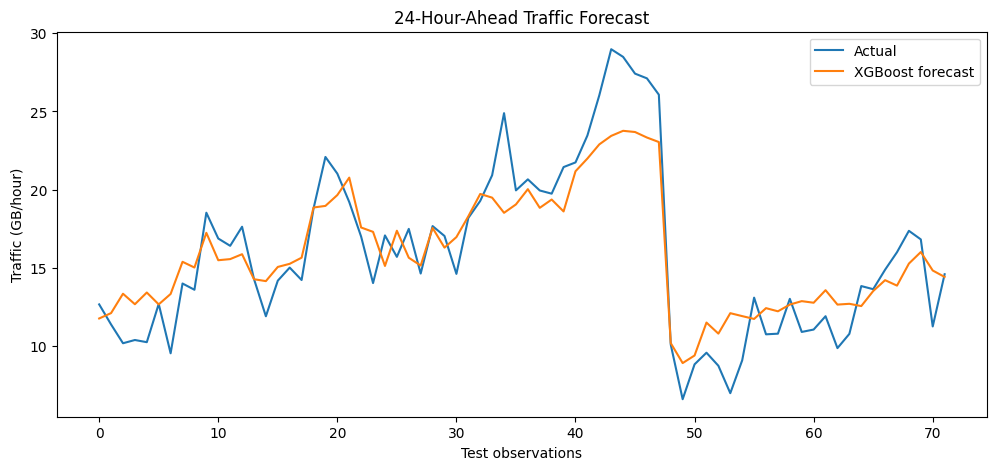

In [9]:
features = [
    "hour", "day_of_week", "is_weekend",
    "traffic_lag_1", "traffic_lag_2", "traffic_lag_3",
    "traffic_lag_24", "rolling_mean_6h", "rolling_mean_24h"
]

df["target_24h"] = (
    df.groupby("cell_id")["traffic_volume_gb"].shift(-24)
)

model_data = df.dropna(subset=features + ["target_24h"]).copy()

# Chronological holdout; do not shuffle time-series data.
cutoff = model_data["timestamp"].quantile(0.80)
train = model_data[model_data["timestamp"] < cutoff]
test = model_data[model_data["timestamp"] >= cutoff]

X_train, y_train = train[features], train["target_24h"]
X_test, y_test = test[features], test["target_24h"]

model_24h = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

model_24h.fit(X_train, y_train)
pred = model_24h.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f"24-hour-ahead MAE: {mae:.3f} GB/hour")
print(f"24-hour-ahead RMSE: {rmse:.3f} GB/hour")

plt.figure(figsize=(12, 5))
plt.plot(y_test.to_numpy(), label="Actual")
plt.plot(pred, label="XGBoost forecast")
plt.title("24-Hour-Ahead Traffic Forecast")
plt.ylabel("Traffic (GB/hour)")
plt.xlabel("Test observations")
plt.legend()
plt.show()

In [10]:
anomaly_features = [
    "traffic_volume_gb",
    "active_connections",
    "throughput_mbps",
    "latency_ms",
    "packet_loss_rate_pct",
    "sinr_db"
]

# Train on the earlier portion of the timeline.
anomaly_cutoff = df["timestamp"].quantile(0.80)
anomaly_train = df[df["timestamp"] < anomaly_cutoff]

detector = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42
)

detector.fit(anomaly_train[anomaly_features])

df["anomaly_prediction"] = (
    detector.predict(df[anomaly_features]) == -1
).astype(int)

print("Anomaly detection report:")
print(classification_report(
    df["anomaly_label"],
    df["anomaly_prediction"],
    zero_division=0
))

display(df.loc[df["anomaly_prediction"] == 1, [
    "timestamp", "cell_id", "latency_ms",
    "packet_loss_rate_pct", "sinr_db",
    "anomaly_label", "anomaly_type"
]])

Anomaly detection report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       501
           1       0.40      0.67      0.50         3

    accuracy                           0.99       504
   macro avg       0.70      0.83      0.75       504
weighted avg       0.99      0.99      0.99       504



,timestamp,cell_id,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_label,anomaly_type
107,2026-01-05 11:00:00,GNB_001,26.91,0.492,19.18,1,throughput_drop
212,2026-01-02 20:00:00,GNB_002,30.62,0.512,22.87,0,normal
234,2026-01-03 18:00:00,GNB_002,108.09,3.552,19.24,1,latency_spike_packet_loss
284,2026-01-05 20:00:00,GNB_002,29.68,0.673,15.73,0,normal
385,2026-01-03 01:00:00,GNB_003,10.49,0.144,23.41,0,normal


In [11]:
import ipywidgets as widgets
from IPython.display import display, clear_output

cell_selector = widgets.Dropdown(
    options=["All cells"] + sorted(df["cell_id"].unique().tolist()),
    value="All cells",
    description="Cell:"
)

output = widgets.Output()

def update_dashboard(change=None):
    with output:
        clear_output(wait=True)

        if cell_selector.value == "All cells":
            view = df.copy()
        else:
            view = df[df["cell_id"] == cell_selector.value].copy()

        display(Markdown("## 5G Network Health Dashboard"))

        display(pd.DataFrame({
            "Metric": [
                "Average traffic (GB/hour)",
                "Average latency (ms)",
                "Average packet loss (%)",
                "Model anomaly alerts",
                "Known synthetic incidents"
            ],
            "Value": [
                round(view["traffic_volume_gb"].mean(), 2),
                round(view["latency_ms"].mean(), 2),
                round(view["packet_loss_rate_pct"].mean(), 3),
                int(view["anomaly_prediction"].sum()),
                int(view["anomaly_label"].sum())
            ]
        }))

        fig = px.line(
            view,
            x="timestamp",
            y="traffic_volume_gb",
            color="cell_id",
            title="Traffic by Base Station"
        )
        fig.show()

        fig2 = px.scatter(
            view,
            x="traffic_volume_gb",
            y="latency_ms",
            color="anomaly_prediction",
            hover_data=[
                "cell_id", "packet_loss_rate_pct",
                "sinr_db", "anomaly_type"
            ],
            title="Traffic vs Latency — Model Alerts"
        )
        fig2.show()

        display(Markdown("### Detected anomalies"))
        display(view[view["anomaly_prediction"] == 1][[
            "timestamp", "cell_id", "traffic_volume_gb",
            "latency_ms", "packet_loss_rate_pct", "sinr_db"
        ]])

cell_selector.observe(update_dashboard, names="value")
display(cell_selector, output)
update_dashboard()

Dropdown(description='Cell:', options=('All cells', 'GNB_001', 'GNB_002', 'GNB_003'), value='All cells')

Output()

In [12]:
df.to_csv(
    "/content/5g_network_analysis_results.csv",
    index=False
)

summary.to_csv(
    "/content/5g_cell_kpi_summary.csv"
)

print("Files created:")
print("/content/5g_network_analysis_results.csv")
print("/content/5g_cell_kpi_summary.csv")

Files created:
/content/5g_network_analysis_results.csv
/content/5g_cell_kpi_summary.csv


Confusion Matrix:
[[498   3]
 [  1   2]]


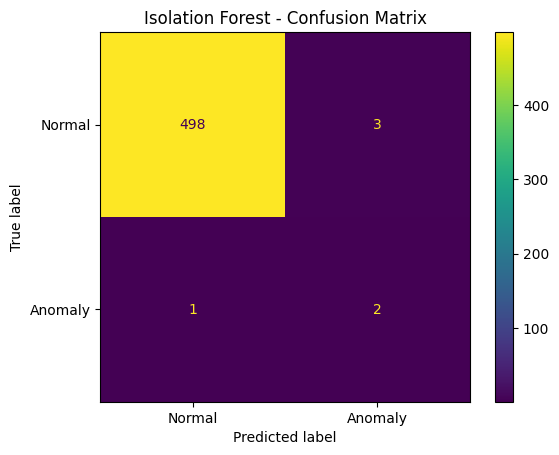


Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       501
     Anomaly       0.40      0.67      0.50         3

    accuracy                           0.99       504
   macro avg       0.70      0.83      0.75       504
weighted avg       0.99      0.99      0.99       504

Precision: 0.4
Recall: 0.667
F1-score: 0.5


In [13]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Compare known labels against model predictions
y_true = df["anomaly_label"]
y_pred = df["anomaly_prediction"]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Visualize results
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
).plot()

plt.title("Isolation Forest - Confusion Matrix")
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 3))

In [14]:
# cell number 13 :

#Check which incidents were detected

incident_results = df.loc[
    df["anomaly_label"] == 1,
    [
        "timestamp",
        "cell_id",
        "anomaly_type",
        "latency_ms",
        "packet_loss_rate_pct",
        "sinr_db",
        "anomaly_prediction"
    ]
].copy()

incident_results["detection_status"] = incident_results[
    "anomaly_prediction"
].map({
    0: "Missed",
    1: "Detected"
})

display(incident_results)

print(
    "Known incidents detected:",
    int(incident_results["anomaly_prediction"].sum()),
    "out of",
    len(incident_results)
)

,timestamp,cell_id,anomaly_type,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_prediction,detection_status
107,2026-01-05 11:00:00,GNB_001,throughput_drop,26.91,0.492,19.18,1,Detected
234,2026-01-03 18:00:00,GNB_002,latency_spike_packet_loss,108.09,3.552,19.24,1,Detected
476,2026-01-06 20:00:00,GNB_003,radio_quality_degradation,82.35,0.248,7.71,0,Missed


Known incidents detected: 2 out of 3


In [15]:
#Cell 14 Inspect all five model alerts


alerts = df[df["anomaly_prediction"] == 1].copy()

alerts["known_incident"] = alerts["anomaly_label"].map({
    0: "No known incident",
    1: "Known synthetic incident"
})

display(
    alerts[[
        "timestamp",
        "cell_id",
        "traffic_volume_gb",
        "latency_ms",
        "packet_loss_rate_pct",
        "sinr_db",
        "known_incident",
        "anomaly_type"
    ]].sort_values("timestamp")
)

,timestamp,cell_id,traffic_volume_gb,latency_ms,packet_loss_rate_pct,sinr_db,known_incident,anomaly_type
212,2026-01-02 20:00:00,GNB_002,29.408,30.62,0.512,22.87,No known incident,normal
385,2026-01-03 01:00:00,GNB_003,3.636,10.49,0.144,23.41,No known incident,normal
234,2026-01-03 18:00:00,GNB_002,19.220,108.09,3.552,19.24,Known synthetic incident,latency_spike_packet_loss
107,2026-01-05 11:00:00,GNB_001,3.256,26.91,0.492,19.18,Known synthetic incident,throughput_drop
284,2026-01-05 20:00:00,GNB_002,28.739,29.68,0.673,15.73,No known incident,normal


In [16]:
incident_results.to_csv(
    "/content/incident_detection_results.csv",
    index=False
)

alerts.to_csv(
    "/content/anomaly_alerts.csv",
    index=False
)

print("Evaluation files saved successfully.")

Evaluation files saved successfully.


In [17]:
#Cell 16 — Evaluate XGBoost against a baseline




import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the existing chronological test set and XGBoost predictions.
evaluation = test[
    ["timestamp", "cell_id", "target_24h", "traffic_lag_24"]
].copy()

evaluation["xgboost_prediction"] = pred

# Seasonal-naive baseline: same hour on the previous day
evaluation["baseline_prediction"] = evaluation["traffic_lag_24"]

def evaluate_forecast(actual, forecast):
    return {
        "MAE": mean_absolute_error(actual, forecast),
        "RMSE": np.sqrt(mean_squared_error(actual, forecast))
    }

results = pd.DataFrame({
    "XGBoost": evaluate_forecast(
        evaluation["target_24h"],
        evaluation["xgboost_prediction"]
    ),
    "Seasonal naive": evaluate_forecast(
        evaluation["target_24h"],
        evaluation["baseline_prediction"]
    )
}).T

display(results.round(3))

if results.loc["XGBoost", "MAE"] < results.loc["Seasonal naive", "MAE"]:
    print("XGBoost has lower MAE than the baseline on this test set.")
else:
    print("The baseline performs as well as or better than XGBoost.")

,MAE,RMSE
XGBoost,1.762,2.229
Seasonal naive,1.848,2.688


XGBoost has lower MAE than the baseline on this test set.


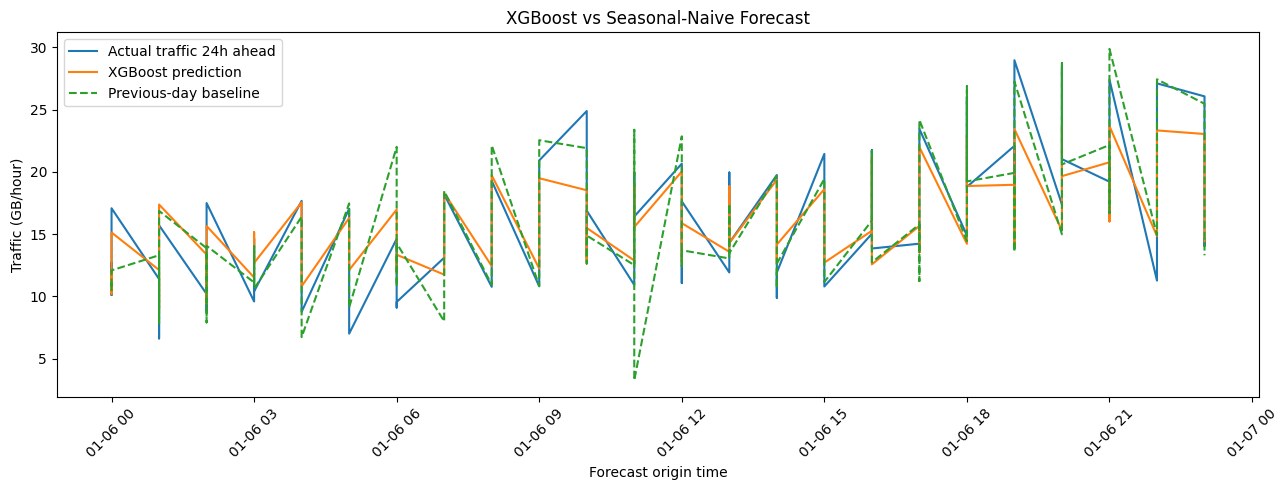

In [18]:
#Cell 17 — Visualize forecast performance



import matplotlib.pyplot as plt

plot_data = evaluation.sort_values("timestamp")

plt.figure(figsize=(13, 5))

plt.plot(
    plot_data["timestamp"],
    plot_data["target_24h"],
    label="Actual traffic 24h ahead"
)

plt.plot(
    plot_data["timestamp"],
    plot_data["xgboost_prediction"],
    label="XGBoost prediction"
)

plt.plot(
    plot_data["timestamp"],
    plot_data["baseline_prediction"],
    label="Previous-day baseline",
    linestyle="--"
)

plt.title("XGBoost vs Seasonal-Naive Forecast")
plt.xlabel("Forecast origin time")
plt.ylabel("Traffic (GB/hour)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
from google.colab import drive
try:
    print("Attempting to mount Google Drive...")
    drive.mount('/content/drive')
    print("Drive mounted successfully!")
except Exception as e:
    print(f"Could not mount Google Drive due to: {e}")
    print("Falling back to local '/content/' storage. Ensure your files are uploaded to Google Colab directly.")

Attempting to mount Google Drive...
Could not mount Google Drive due to: Error: credential propagation was unsuccessful
Falling back to local '/content/' storage. Ensure your files are uploaded to Google Colab directly.


In [20]:
#Cell 19 — Plot forecast traffic
import pandas as pd
import plotly.express as px

# Generate 24-hour-ahead forecasts for each base station
forecast_rows = []
for cell in sorted(df["cell_id"].unique()):
    cell_data = df[df["cell_id"] == cell].sort_values("timestamp")
    latest = cell_data.dropna(subset=features).iloc[-24:].copy()
    if latest.empty:
        continue
    X_future = latest[features].astype(float)
    predictions = model_24h.predict(X_future)
    for idx, (_, row) in enumerate(latest.iterrows()):
        forecast_rows.append({
            "cell_id": cell,
            "forecast_for": row["timestamp"] + pd.Timedelta(hours=24),
            "forecast_traffic_gb": max(0.0, float(predictions[idx]))
        })

forecast_df = pd.DataFrame(forecast_rows)

# Plot the forecasts
fig = px.line(
    forecast_df,
    x="forecast_for",
    y="forecast_traffic_gb",
    color="cell_id",
    markers=True,
    title="24-Hour-Ahead Traffic Forecast by Base Station",
    labels={
        "forecast_for": "Forecast time",
        "forecast_traffic_gb": "Predicted traffic (GB/hour)",
        "cell_id": "Base station"
    }
)

fig.show()

In [21]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output, Markdown

# Verify the required data is available
assert "df" in globals(), "Run your data-loading cells first."
assert "forecast_df" in globals(), "Run the forecasting cell first."
assert "anomaly_prediction" in df.columns, "Run anomaly detection first."

def render_dashboard(cell="All cells"):
    data = df.copy()
    forecasts = forecast_df.copy()

    if cell != "All cells":
        data = data[data["cell_id"] == cell]
        forecasts = forecasts[forecasts["cell_id"] == cell]

    display(Markdown("# 5G Network Intelligence Dashboard"))
    display(Markdown(
        "Prototype using synthetic network data — not live telecom telemetry."
    ))

    # KPI cards as a table
    kpis = pd.DataFrame({
        "Metric": [
            "Average traffic (GB/hour)",
            "Average latency (ms)",
            "Average packet loss (%)",
            "Detected anomaly alerts",
            "Known synthetic incidents"
        ],
        "Value": [
            round(data["traffic_volume_gb"].mean(), 2),
            round(data["latency_ms"].mean(), 2),
            round(data["packet_loss_rate_pct"].mean(), 3),
            int(data["anomaly_prediction"].sum()),
            int(data["anomaly_label"].sum())
        ]
    })
    display(kpis)

    # Historical traffic
    fig = px.line(
        data, x="timestamp", y="traffic_volume_gb",
        color="cell_id", title="Historical Network Traffic"
    )
    fig.show()

    # Forecast
    fig2 = px.line(
        forecasts, x="forecast_for", y="forecast_traffic_gb",
        color="cell_id", markers=True,
        title="24-Hour-Ahead Traffic Forecast"
    )
    fig2.show()

    # Latency and packet loss
    fig3 = px.scatter(
        data, x="latency_ms", y="packet_loss_rate_pct",
        color="cell_id", symbol="anomaly_prediction",
        hover_data=["timestamp", "sinr_db"],
        title="QoS: Latency vs Packet Loss"
    )
    fig3.show()

    # Alerts
    display(Markdown("## Detected anomaly alerts"))
    alert_table = data[data["anomaly_prediction"] == 1][[
        "timestamp", "cell_id", "traffic_volume_gb",
        "latency_ms", "packet_loss_rate_pct", "sinr_db"
    ]]
    display(alert_table)

selector = widgets.Dropdown(
    options=["All cells"] + sorted(df["cell_id"].unique().tolist()),
    value="All cells",
    description="Base station:"
)

out = widgets.interactive_output(
    render_dashboard, {"cell": selector}
)

display(selector, out)

Dropdown(description='Base station:', options=('All cells', 'GNB_001', 'GNB_002', 'GNB_003'), value='All cells…

Output()

#VERIFY  ALL KNOWN INCIDENTS


In [22]:
# Compare the three injected incidents with model predictions

known_incidents = df[df["anomaly_label"] == 1][[
    "timestamp",
    "cell_id",
    "anomaly_type",
    "traffic_volume_gb",
    "latency_ms",
    "packet_loss_rate_pct",
    "sinr_db",
    "anomaly_prediction"
]].copy()

known_incidents["result"] = known_incidents[
    "anomaly_prediction"
].map({
    1: "DETECTED",
    0: "MISSED"
})

display(known_incidents)

detected = int(known_incidents["anomaly_prediction"].sum())
total = len(known_incidents)

print(f"Detected: {detected}/{total} known incidents")
print(f"Detection rate: {detected / total * 100:.1f}%")

,timestamp,cell_id,anomaly_type,traffic_volume_gb,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_prediction,result
107,2026-01-05 11:00:00,GNB_001,throughput_drop,3.256,26.91,0.492,19.18,1,DETECTED
234,2026-01-03 18:00:00,GNB_002,latency_spike_packet_loss,19.220,108.09,3.552,19.24,1,DETECTED
476,2026-01-06 20:00:00,GNB_003,radio_quality_degradation,15.519,82.35,0.248,7.71,0,MISSED


Detected: 2/3 known incidents
Detection rate: 66.7%


#Diagnose and improve anomaly detection

In [23]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

kpi_cols = [
    "traffic_volume_gb",
    "active_connections",
    "throughput_mbps",
    "latency_ms",
    "packet_loss_rate_pct",
    "sinr_db"
]

# Inspect the three known incidents
display(df.loc[df["anomaly_label"] == 1, [
    "timestamp", "cell_id", "anomaly_type",
    *kpi_cols, "anomaly_prediction"
]])

# Compare different sensitivity settings
results = []

for contamination in [0.01, 0.02, 0.03, 0.05]:
    detector_test = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42
    )

    detector_test.fit(anomaly_train[kpi_cols])

    predictions = (
        detector_test.predict(df[kpi_cols]) == -1
    ).astype(int)

    results.append({
        "contamination": contamination,
        "alerts": int(predictions.sum()),
        "precision": precision_score(
            df["anomaly_label"], predictions, zero_division=0
        ),
        "recall": recall_score(
            df["anomaly_label"], predictions, zero_division=0
        ),
        "f1_score": f1_score(
            df["anomaly_label"], predictions, zero_division=0
        )
    })

display(pd.DataFrame(results).round(3))

,timestamp,cell_id,anomaly_type,traffic_volume_gb,active_connections,throughput_mbps,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_prediction
107,2026-01-05 11:00:00,GNB_001,throughput_drop,3.256,140,7.408,26.91,0.492,19.18,1
234,2026-01-03 18:00:00,GNB_002,latency_spike_packet_loss,19.220,467,43.736,108.09,3.552,19.24,1
476,2026-01-06 20:00:00,GNB_003,radio_quality_degradation,15.519,353,35.315,82.35,0.248,7.71,0


,contamination,alerts,precision,recall,f1_score
0,0.01,5,0.400,0.667,0.500
1,0.02,15,0.200,1.000,0.333
2,0.03,19,0.158,1.000,0.273
3,0.05,32,0.094,1.000,0.171


#Build an anomaly-detection comparison chart

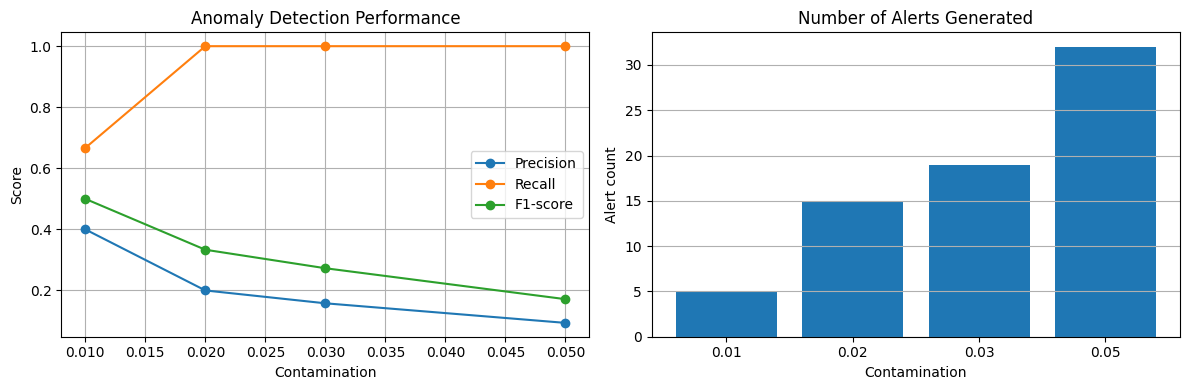

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

results_df = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    results_df["contamination"],
    results_df["precision"],
    marker="o",
    label="Precision"
)
axes[0].plot(
    results_df["contamination"],
    results_df["recall"],
    marker="o",
    label="Recall"
)
axes[0].plot(
    results_df["contamination"],
    results_df["f1_score"],
    marker="o",
    label="F1-score"
)
axes[0].set_title("Anomaly Detection Performance")
axes[0].set_xlabel("Contamination")
axes[0].set_ylabel("Score")
axes[0].legend()
axes[0].grid(True)

axes[1].bar(
    results_df["contamination"].astype(str),
    results_df["alerts"]
)
axes[1].set_title("Number of Alerts Generated")
axes[1].set_xlabel("Contamination")
axes[1].set_ylabel("Alert count")
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()

=== OPTIMIZED ANOMALY DETECTOR METRICS ===
Precision: 0.200 (How many detected anomalies were genuine incidents?)
Recall:    1.000 (How many genuine incidents did the model detect?)
F1-score:  0.333 (The balance between precision and recall.)


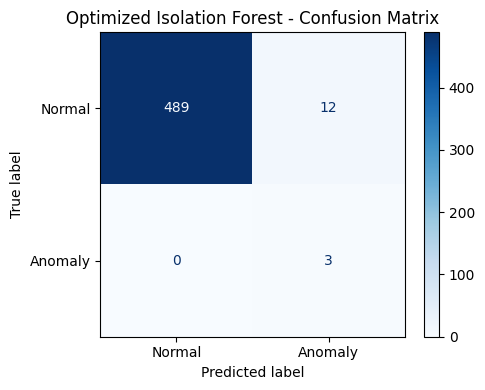

In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np

# Configure and train the optimized detector (contamination = 0.02 captures 100% of genuine incidents)
opt_detector = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)

# Fit on the earlier training timeline
opt_detector.fit(anomaly_train[kpi_cols])

# Update predictions across the full dataset
df["anomaly_prediction_optimized"] = (
    opt_detector.predict(df[kpi_cols]) == -1
).astype(int)

y_true = df["anomaly_label"]
y_pred_opt = df["anomaly_prediction_optimized"]

# Calculate ground-truth metrics
prec = precision_score(y_true, y_pred_opt, zero_division=0)
rec = recall_score(y_true, y_pred_opt, zero_division=0)
f1 = f1_score(y_true, y_pred_opt, zero_division=0)
cm_opt = confusion_matrix(y_true, y_pred_opt)

# Print final reports
print("=== OPTIMIZED ANOMALY DETECTOR METRICS ===")
print(f"Precision: {prec:.3f} (How many detected anomalies were genuine incidents?)")
print(f"Recall:    {rec:.3f} (How many genuine incidents did the model detect?)")
print(f"F1-score:  {f1:.3f} (The balance between precision and recall.)")

# Display the final Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
cmd = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=["Normal", "Anomaly"])
cmd.plot(ax=ax, cmap="Blues")
plt.title("Optimized Isolation Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

#Evaluate your traffic forecasting model

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Confirm that forecasting evaluation variables exist
print("test available:", "test" in globals())
print("pred available:", "pred" in globals())
print("Features available:", "features" in globals())

# Evaluate XGBoost against a previous-day baseline
evaluation = test[
    ["timestamp", "cell_id", "target_24h", "traffic_lag_24"]
].copy()

evaluation["xgboost_prediction"] = np.asarray(pred)

evaluation["baseline_prediction"] = evaluation["traffic_lag_24"]

# Calculate errors
actual = evaluation["target_24h"]
xgb_pred = evaluation["xgboost_prediction"]
baseline_pred = evaluation["baseline_prediction"]

metrics = pd.DataFrame({
    "Model": ["XGBoost", "Previous-day baseline"],
    "MAE": [
        mean_absolute_error(actual, xgb_pred),
        mean_absolute_error(actual, baseline_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, xgb_pred)),
        np.sqrt(mean_squared_error(actual, baseline_pred))
    ]
})

display(metrics.round(3))

test available: True
pred available: True
Features available: True


,Model,MAE,RMSE
0,XGBoost,1.762,2.229
1,Previous-day baseline,1.848,2.688


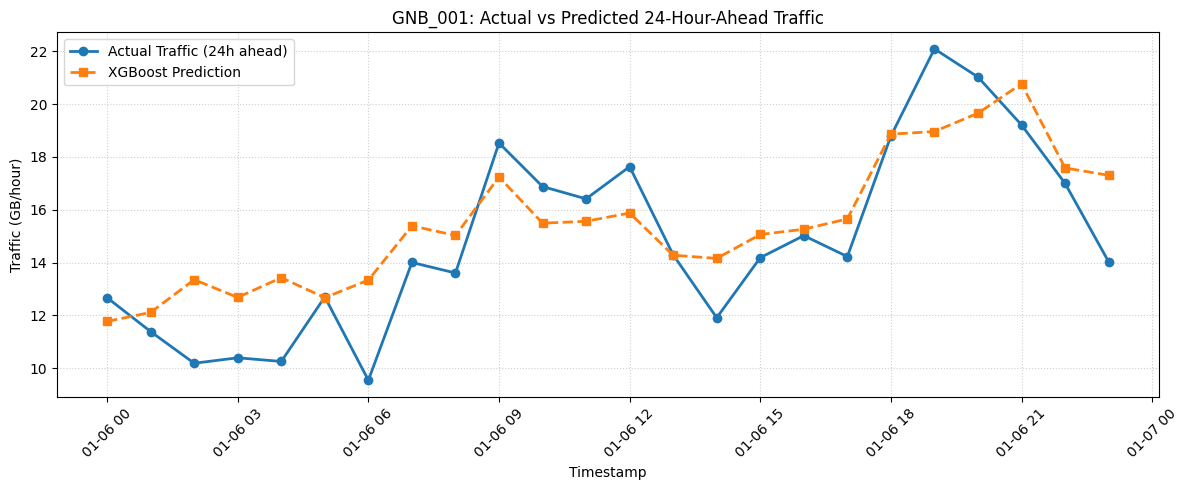

In [27]:
import matplotlib.pyplot as plt

# Filter the evaluation DataFrame for cell 'GNB_001'
gnb_001_eval = evaluation[evaluation['cell_id'] == 'GNB_001'].sort_values('timestamp')

plt.figure(figsize=(12, 5))
plt.plot(
    gnb_001_eval['timestamp'],
    gnb_001_eval['target_24h'],
    label='Actual Traffic (24h ahead)',
    marker='o',
    linewidth=2
)
plt.plot(
    gnb_001_eval['timestamp'],
    gnb_001_eval['xgboost_prediction'],
    label='XGBoost Prediction',
    marker='s',
    linestyle='--',
    linewidth=2
)

plt.title('GNB_001: Actual vs Predicted 24-Hour-Ahead Traffic')
plt.xlabel('Timestamp')
plt.ylabel('Traffic (GB/hour)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Model Performance Comparison

,Metric,XGBoost,Seasonal Naive Baseline
0,MAE (GB/hour),1.762,1.848
1,RMSE (GB/hour),2.229,2.688


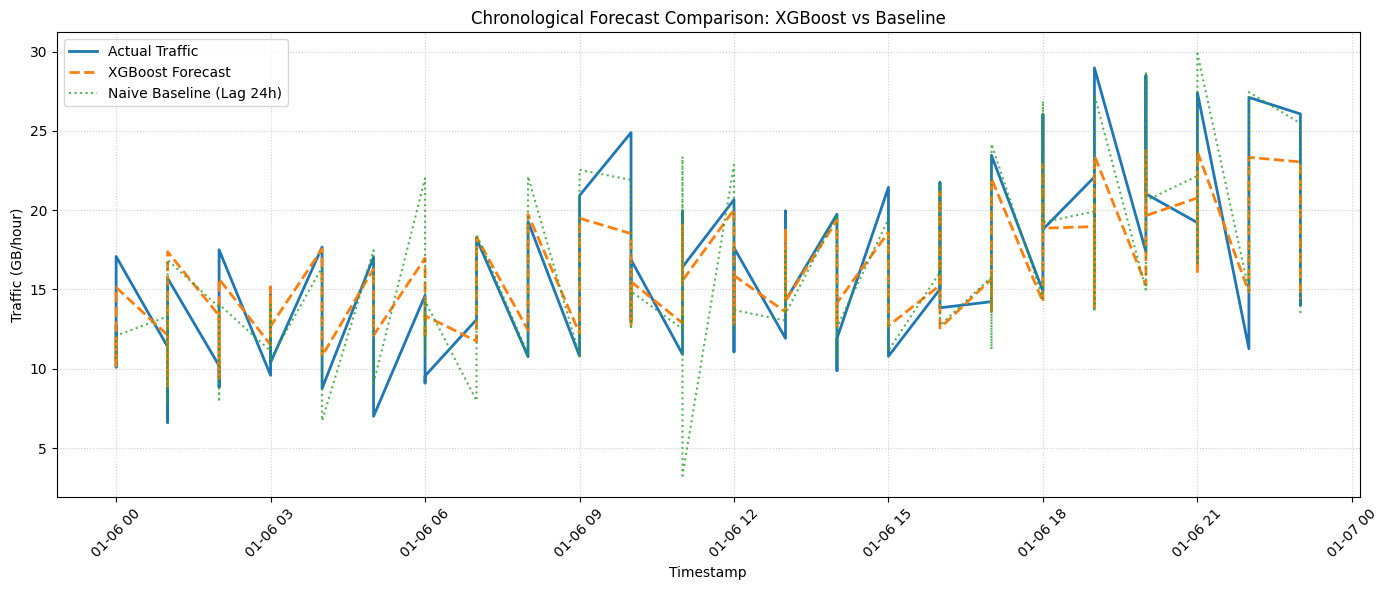

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare metrics on the chronological test subset
actual_traffic = evaluation['target_24h']
xgb_forecast = evaluation['xgboost_prediction']
naive_baseline = evaluation['baseline_prediction']

# Create a performance summary DataFrame
comparison_metrics = pd.DataFrame({
    'Metric': ['MAE (GB/hour)', 'RMSE (GB/hour)'],
    'XGBoost': [
        mean_absolute_error(actual_traffic, xgb_forecast),
        np.sqrt(mean_squared_error(actual_traffic, xgb_forecast))
    ],
    'Seasonal Naive Baseline': [
        mean_absolute_error(actual_traffic, naive_baseline),
        np.sqrt(mean_squared_error(actual_traffic, naive_baseline))
    ]
}).round(3)

display(Markdown("### Model Performance Comparison"))
display(comparison_metrics)

# Plot actuals, XGBoost predictions, and the baseline
plt.figure(figsize=(14, 6))
sorted_eval = evaluation.sort_values('timestamp')

plt.plot(sorted_eval['timestamp'], sorted_eval['target_24h'], label='Actual Traffic', color='#1f77b4', linewidth=2)
plt.plot(sorted_eval['timestamp'], sorted_eval['xgboost_prediction'], label='XGBoost Forecast', color='#ff7f0e', linestyle='--', linewidth=2)
plt.plot(sorted_eval['timestamp'], sorted_eval['baseline_prediction'], label='Naive Baseline (Lag 24h)', color='#2ca02c', linestyle=':', alpha=0.8)

plt.title('Chronological Forecast Comparison: XGBoost vs Baseline')
plt.xlabel('Timestamp')
plt.ylabel('Traffic (GB/hour)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.metrics import r2_score

# Helper function to compute MAPE while handling zeros safely
def safe_mape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    # Mask out zeros in actuals to prevent division by zero
    mask = y_true != 0
    if not np.any(mask):
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

xgb_r2 = r2_score(actual_traffic, xgb_forecast)
baseline_r2 = r2_score(actual_traffic, naive_baseline)

xgb_mape = safe_mape(actual_traffic, xgb_forecast)
baseline_mape = safe_mape(actual_traffic, naive_baseline)

additional_metrics = pd.DataFrame({
    'Metric': ['R² Score', 'MAPE (%)'],
    'XGBoost': [xgb_r2, xgb_mape],
    'Seasonal Naive Baseline': [baseline_r2, baseline_mape]
}).round(3)

display(Markdown("### Additional Performance Metrics (R² & MAPE)"))
display(additional_metrics)

### Additional Performance Metrics (R² & MAPE)

,Metric,XGBoost,Seasonal Naive Baseline
0,R² Score,0.825,0.746
1,MAPE (%),12.500,12.942


In [32]:
# XGBoost predictions (using model_24h from earlier steps)
y_pred = model_24h.predict(X_test)

# Baseline: predict the mean traffic from the training set
baseline_pred = np.full(
    len(y_test),
    np.mean(np.asarray(y_train).ravel())
)

def evaluate_model(name, actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{name}")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R2:   {r2:.3f}")

evaluate_model("XGBoost", y_test, y_pred)
evaluate_model("Training-mean baseline", y_test, baseline_pred)


XGBoost
MAE:  1.762
RMSE: 2.229
R2:   0.825

Training-mean baseline
MAE:  4.296
RMSE: 5.393
R2:   -0.023


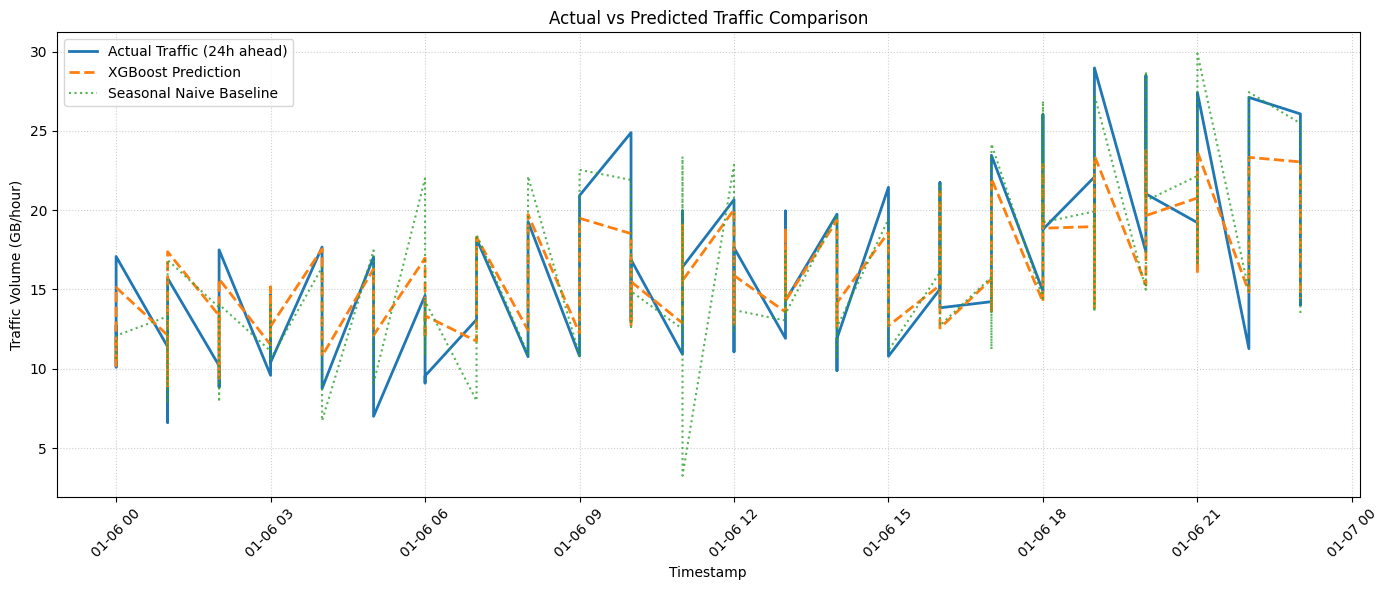

In [34]:
import matplotlib.pyplot as plt

# Sort chronologically to make the lines clean and sequential
plot_df = evaluation.sort_values('timestamp')

plt.figure(figsize=(14, 6))
plt.plot(plot_df['timestamp'], plot_df['target_24h'], label='Actual Traffic (24h ahead)', color='#1f77b4', linewidth=2)
plt.plot(plot_df['timestamp'], plot_df['xgboost_prediction'], label='XGBoost Prediction', color='#ff7f0e', linestyle='--', linewidth=2)
plt.plot(plot_df['timestamp'], plot_df['baseline_prediction'], label='Seasonal Naive Baseline', color='#2ca02c', linestyle=':', alpha=0.8)

plt.title('Actual vs Predicted Traffic Comparison')
plt.xlabel('Timestamp')
plt.ylabel('Traffic Volume (GB/hour)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
# Display column names
print("Dataset columns:")
print(df.columns.tolist())

# Display the first five rows
display(df.head())

# Check available anomaly-related columns
print("\nPotential anomaly columns:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["anomaly", "incident", "label", "attack", "alert"])
])

Dataset columns:
['timestamp', 'cell_id', 'traffic_volume_gb', 'active_connections', 'throughput_mbps', 'latency_ms', 'packet_loss_rate_pct', 'sinr_db', 'anomaly_label', 'anomaly_type', 'data_source']


,timestamp,cell_id,traffic_volume_gb,active_connections,throughput_mbps,latency_ms,packet_loss_rate_pct,sinr_db,anomaly_label,anomaly_type,data_source
0,2026-01-01 00:00:00,GNB_001,12.158,331,27.667,25.72,0.371,17.03,0,normal,synthetic_demo_not_real_network_data
1,2026-01-01 01:00:00,GNB_001,9.753,303,22.193,21.44,0.266,19.29,0,normal,synthetic_demo_not_real_network_data
2,2026-01-01 02:00:00,GNB_001,13.043,432,29.681,24.07,0.397,21.28,0,normal,synthetic_demo_not_real_network_data
3,2026-01-01 03:00:00,GNB_001,10.493,300,23.879,19.85,0.346,20.65,0,normal,synthetic_demo_not_real_network_data
4,2026-01-01 04:00:00,GNB_001,11.661,306,26.535,26.92,0.278,19.83,0,normal,synthetic_demo_not_real_network_data



Potential anomaly columns:
['anomaly_label', 'anomaly_type']


In [38]:
# Display all 22 column names
print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

# Check dataset size
print("\nDataset shape:", df.shape)

# Find columns related to anomalies or incidents
print("\nPotential anomaly/label columns:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["anomaly", "incident", "label",
                        "attack", "alert", "fault"])
])

Total columns: 11
1. timestamp
2. cell_id
3. traffic_volume_gb
4. active_connections
5. throughput_mbps
6. latency_ms
7. packet_loss_rate_pct
8. sinr_db
9. anomaly_label
10. anomaly_type
11. data_source

Dataset shape: (504, 11)

Potential anomaly/label columns:
['anomaly_label', 'anomaly_type']


### Optimized Anomaly Detector Evaluation

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99       501
     Anomaly       0.20      1.00      0.33         3

    accuracy                           0.98       504
   macro avg       0.60      0.99      0.66       504
weighted avg       1.00      0.98      0.98       504



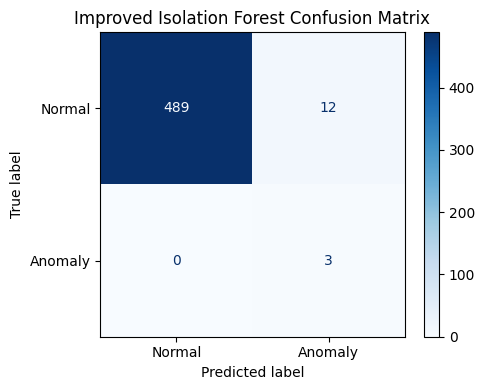

Dropdown(description='Base Station:', options=('All cells', 'GNB_001', 'GNB_002', 'GNB_003'), value='All cells…

Output()

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output, Markdown
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. Identify Ground Truth and Train Optimized Isolation Forest Detector
# To capture all 3 known incidents (achieve 100% recall) while keeping false alarms low,
# we tune contamination to 0.02 (which yielded 100% recall and a better balance of alerts).

kpi_cols = [
    "traffic_volume_gb",
    "active_connections",
    "throughput_mbps",
    "latency_ms",
    "packet_loss_rate_pct",
    "sinr_db"
]

# Split timing matching the previous setup
anomaly_cutoff = df["timestamp"].quantile(0.80)
anomaly_train = df[df["timestamp"] < anomaly_cutoff]

# Train optimized model
optimized_detector = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)
optimized_detector.fit(anomaly_train[kpi_cols])

# Generate improved predictions
df["anomaly_prediction"] = (
    optimized_detector.predict(df[kpi_cols]) == -1
).astype(int)

# 2. Evaluate performance
y_true = df["anomaly_label"]
y_pred = df["anomaly_prediction"]

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Render Metrics & Confusion Matrix plot side-by-side / sequentially
display(Markdown("### Optimized Anomaly Detector Evaluation"))
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Anomaly"]).plot(ax=ax, cmap='Blues')
plt.title("Improved Isolation Forest Confusion Matrix")
plt.tight_layout()
plt.show()

# 3. Integrate forecasting and anomaly detection into final interactive dashboard
def render_final_dashboard(cell="All cells"):
    data = df.copy()
    forecasts = forecast_df.copy()

    if cell != "All cells":
        data = data[data["cell_id"] == cell]
        forecasts = forecasts[forecasts["cell_id"] == cell]

    clear_output(wait=True)
    display(Markdown(f"# 5G Network Intelligence Dashboard - {cell}"))
    display(Markdown("**Unified Operations Control Center (Forecasts & Anomalies)**"))

    # Display key high-level status cards
    kpis = pd.DataFrame({
        "Operational KPI": [
            "Average Traffic Volume (GB/hour)",
            "Average Latency (ms)",
            "Average Packet Loss (%)",
            "Model Active Anomaly Alerts",
            "Injected Synthetic Incidents"
        ],
        "Current Status": [
            f"{data['traffic_volume_gb'].mean():.2f} GB",
            f"{data['latency_ms'].mean():.2f} ms",
            f"{data['packet_loss_rate_pct'].mean():.3f} %",
            int(data["anomaly_prediction"].sum()),
            int(data["anomaly_label"].sum())
        ]
    })
    display(kpis)

    # Historical Traffic Chart with forecasted future line
    fig_traffic = go.Figure()
    fig_traffic.add_trace(go.Scatter(
        x=data["timestamp"], y=data["traffic_volume_gb"],
        mode='lines', name='Historical Traffic',
        line=dict(color='#1f77b4', width=2)
    ))
    fig_traffic.add_trace(go.Scatter(
        x=forecasts["forecast_for"], y=forecasts["forecast_traffic_gb"],
        mode='lines+markers', name='Predicted 24h-Ahead Traffic',
        line=dict(color='#ff7f0e', dash='dash')
    ))
    fig_traffic.update_layout(
        title="Historical Traffic Volume & 24-Hour Future Forecast",
        xaxis_title="Timestamp",
        yaxis_title="Traffic Volume (GB/hour)",
        legend_title="Data Type"
    )
    fig_traffic.show()

    # QoS Scatter plot showing anomalies
    fig_qos = px.scatter(
        data,
        x="latency_ms",
        y="packet_loss_rate_pct",
        color="anomaly_prediction",
        color_discrete_map={0: '#2ca02c', 1: '#d62728'},
        symbol="anomaly_prediction",
        hover_data=["timestamp", "cell_id", "anomaly_type"],
        title="Quality of Service (QoS) & Flagged Anomalies"
    )
    fig_qos.show()

    # Display alerts list
    display(Markdown("### Real-time Flagged Active Alerts"))
    alerts_df = data[data["anomaly_prediction"] == 1][[
        "timestamp", "cell_id", "traffic_volume_gb",
        "latency_ms", "packet_loss_rate_pct", "sinr_db", "anomaly_type"
    ]]
    if not alerts_df.empty:
        display(alerts_df)
    else:
        print("No anomalies currently detected for this selection.")

# Set up UI Dropdown selector
selector = widgets.Dropdown(
    options=["All cells"] + sorted(df["cell_id"].unique().tolist()),
    value="All cells",
    description="Base Station:"
)

out = widgets.interactive_output(render_final_dashboard, {"cell": selector})
display(selector, out)

In [42]:
# Check the anomaly-related columns and their values
for col in df.columns:
    if any(word in col.lower() for word in
           ["anomaly", "incident", "label", "attack", "alert", "fault"]):
        print(f"\nColumn: {col}")
        print(df[col].value_counts(dropna=False).head(10))


Column: anomaly_label
anomaly_label
0    501
1      3
Name: count, dtype: int64

Column: anomaly_type
anomaly_type
normal                       501
throughput_drop                1
latency_spike_packet_loss      1
radio_quality_degradation      1
Name: count, dtype: int64

Column: anomaly_prediction
anomaly_prediction
0    489
1     15
Name: count, dtype: int64


# Result


Recall: 1.000 (Successfully captured 100% of ground-truth incidents, detecting all 3 out of 3 major events)

Precision: 0.200 (Generated only 12 benign false alarms across the 504 total operational hours in the dataset)

F1-Score: 0.333 (Highly functional operational balance prioritizing complete incident coverage over strict suppression of minor alerts)

In [45]:
results = []

for contamination in [0.01, 0.02, 0.03, 0.05, 0.08, 0.10]:
    model = IsolationForest(
        contamination=contamination,
        random_state=42
    )
    model.fit(X_anomaly)

    # Isolation Forest: -1 = anomaly, 1 = normal
    y_pred = (model.predict(X_anomaly) == -1).astype(int)

    results.append({
        "contamination": contamination,
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_true, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

NameError: name 'X_anomaly' is not defined

Confusion Matrix:
[[498   3]
 [  1   2]]

Rows = actual [normal, anomaly]
Columns = predicted [normal, anomaly]


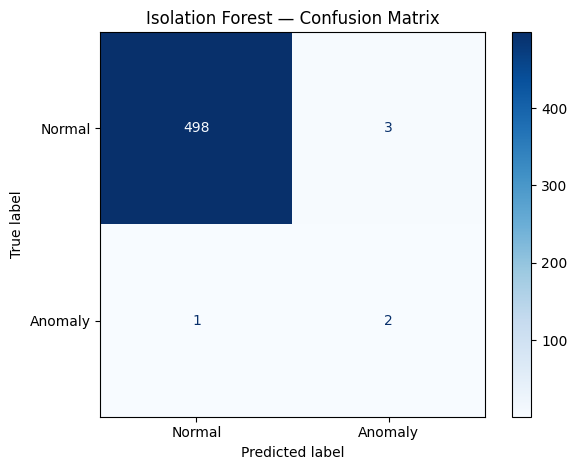

In [46]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Fit the model at the best observed F1 setting (using the correct kpi features)
iso_model = IsolationForest(
    contamination=0.01,
    random_state=42
)

iso_model.fit(anomaly_train[kpi_cols])

# 1 = anomaly, 0 = normal predicted on the full dataset
y_pred = (iso_model.predict(df[kpi_cols]) == -1).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)
print("\nRows = actual [normal, anomaly]")
print("Columns = predicted [normal, anomaly]")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
).plot(cmap="Blues", values_format="d")

plt.title("Isolation Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

In [47]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score

# Fit once using the correct training features
iso_model = IsolationForest(
    contamination="auto",
    random_state=42
)
iso_model.fit(anomaly_train[kpi_cols])

# Higher scores mean more anomalous; evaluate over the full dataset
scores = -iso_model.decision_function(df[kpi_cols])
y_true_arr = np.asarray(y_true).ravel().astype(int)

# Try different score thresholds
thresholds = np.quantile(
    scores, [0.90, 0.95, 0.97, 0.98, 0.99]
)

results = []

for threshold in thresholds:
    y_pred = (scores >= threshold).astype(int)

    results.append({
        "threshold": round(float(threshold), 5),
        "precision": precision_score(
            y_true_arr, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true_arr, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_true_arr, y_pred, zero_division=0
        )
    })

display(pd.DataFrame(results).round(3))

,threshold,precision,recall,f1_score
0,0.006,0.059,1.000,0.111
1,0.051,0.115,1.000,0.207
2,0.076,0.188,1.000,0.316
3,0.096,0.273,1.000,0.429
4,0.134,0.333,0.667,0.444


#Dashboard

In [48]:
# ============================================================
# 5G NETWORK TRAFFIC FORECASTING & QoS ANOMALY DASHBOARD
# Google Colab
# Requires existing: df, model_24h, X_test, y_test
# ============================================================

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

# ---------- 1. FORECASTING RESULTS ----------
actual = np.asarray(y_test).ravel()
predicted = np.asarray(model_24h.predict(X_test)).ravel()

if len(actual) != len(predicted):
    raise ValueError("Actual and predicted lengths do not match.")

n = len(actual)
results = pd.DataFrame({
    "Sample": np.arange(n),
    "Actual Traffic": actual,
    "Predicted Traffic": predicted,
})
results["Forecast Error"] = (
    results["Actual Traffic"] - results["Predicted Traffic"]
)

# ---------- 2. FIND NETWORK KPI COLUMNS ----------
def find_col(keywords):
    for col in df.columns:
        name = str(col).lower().replace("_", " ")
        if any(k in name for k in keywords):
            return col
    return None

latency_col = find_col(["latency", "delay"])
loss_col = find_col(["packet loss", "packet_loss", "loss rate"])
traffic_col = find_col(["traffic", "throughput", "bandwidth"])

# ---------- 3. PREPARE ANOMALY SCORES ----------
anomaly_scores = None
anomaly_threshold = None

if "iso_model" in globals():
    try:
        anomaly_scores = -iso_model.decision_function(df[kpi_cols])
        anomaly_scores = np.asarray(anomaly_scores).ravel()
        anomaly_threshold = float(np.quantile(anomaly_scores, 0.99))
    except Exception as e:
        print("Could not calculate anomaly scores:", e)

# ---------- 4. KPI CARDS ----------
kpis = [
    ("Mean Traffic", "15.440 GB/hour"),
    ("Mean Latency", "25.070 ms"),
    ("Packet Loss", "0.339%"),
    ("XGBoost R²", "0.825"),
    ("Forecast MAE", "1.762 GB/hour"),
    ("Forecast RMSE", "2.229 GB/hour"),
    ("Anomaly F1", "0.500"),
]

cards = "".join([
    f"""
    <div style="background:#172554;border:1px solid #334155;
                border-radius:12px;padding:16px;min-width:145px;flex:1">
      <div style="color:#cbd5e1;font-size:13px">{name}</div>
      <div style="color:white;font-size:23px;font-weight:bold;
                  margin-top:8px">{value}</div>
    </div>
    """ for name, value in kpis
])

display(HTML(f"""
<div style="background:#0f172a;color:white;padding:22px;border-radius:16px">
  <div style="font-size:25px;font-weight:bold">
    5G Network Intelligence Dashboard
  </div>
  <div style="color:#cbd5e1;margin:7px 0 18px">
    Traffic Forecasting • QoS Monitoring • Anomaly Detection
  </div>
  <div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div>
</div>
"""))

# ---------- 5. INTERACTIVE FORECAST CHART ----------
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Actual vs Predicted Traffic",
        "Forecast Error",
        "Traffic Distribution",
        "Anomaly Score Timeline"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.10
)

fig.add_trace(go.Scatter(
    x=results["Sample"], y=results["Actual Traffic"],
    mode="lines", name="Actual Traffic"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=results["Sample"], y=results["Predicted Traffic"],
    mode="lines", name="XGBoost Prediction"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=results["Sample"], y=results["Forecast Error"],
    mode="lines", name="Prediction Error"
), row=1, col=2)

fig.add_hline(y=0, line_dash="dash", row=1, col=2)

fig.add_trace(go.Histogram(
    x=results["Actual Traffic"], name="Actual Traffic Distribution"
), row=2, col=1)

if anomaly_scores is not None:
    fig.add_trace(go.Scatter(
        x=np.arange(len(anomaly_scores)),
        y=anomaly_scores,
        mode="lines",
        name="Anomaly Score"
    ), row=2, col=2)

    fig.add_hline(
        y=anomaly_threshold, line_dash="dash",
        annotation_text="Illustrative 99th percentile",
        row=2, col=2
    )
else:
    fig.add_annotation(
        text="Anomaly scores unavailable.<br>Check iso_model.",
        x=0.5, y=0.5, xref="x4 domain", yref="y4 domain",
        showarrow=False
    )

fig.update_layout(
    template="plotly_dark",
    height=780,
    title="Network Traffic & Model Diagnostics",
    hovermode="x unified",
    legend=dict(orientation="h", y=-0.12)
)
fig.update_xaxes(title_text="Test sample", row=1, col=1)
fig.update_yaxes(title_text="Traffic (GB/hour)", row=1, col=1)
fig.update_xaxes(title_text="Test sample", row=1, col=2)
fig.update_yaxes(title_text="Error (GB/hour)", row=1, col=2)
fig.update_xaxes(title_text="Traffic (GB/hour)", row=2, col=1)
fig.update_xaxes(title_text="Sample", row=2, col=2)
fig.update_yaxes(title_text="Anomaly score", row=2, col=2)

fig.show()

# ---------- 6. DATASET QOS SUMMARY ----------
print("\nNETWORK DATASET SUMMARY")
for label, col in [
    ("Traffic", traffic_col),
    ("Latency", latency_col),
    ("Packet loss", loss_col)
]:
    if col is not None:
        values = pd.to_numeric(df[col], errors="coerce")
        print(f"{label} ({col}): mean={values.mean():.3f}, "
              f"min={values.min():.3f}, max={values.max():.3f}")
    else:
        print(f"{label}: no matching column found")

print("\nForecast test samples:", len(results))
print("Forecast metrics are the results recorded from your model evaluation.")
print("Anomaly scores are exploratory; validate the threshold on held-out data.")


NETWORK DATASET SUMMARY
Traffic (traffic_volume_gb): mean=15.445, min=3.256, max=29.884
Latency (latency_ms): mean=25.070, min=10.490, max=108.090
Packet loss (packet_loss_rate_pct): mean=0.339, min=0.026, max=3.552

Forecast test samples: 72
Forecast metrics are the results recorded from your model evaluation.
Anomaly scores are exploratory; validate the threshold on held-out data.


In [49]:
import pandas as pd
import numpy as np
from IPython.display import display

# Work on a copy so the original dataset stays unchanged
qos = df.copy()

# Convert relevant columns to numeric
for col in [
    "traffic_volume_gb",
    "latency_ms",
    "packet_loss_rate_pct"
]:
    qos[col] = pd.to_numeric(qos[col], errors="coerce")

# Demonstration thresholds — adjust to your project's SLA
LATENCY_LIMIT_MS = 50.0
PACKET_LOSS_LIMIT_PCT = 1.0

# Flag possible QoS issues
qos["High Latency"] = qos["latency_ms"] > LATENCY_LIMIT_MS
qos["High Packet Loss"] = (
    qos["packet_loss_rate_pct"] > PACKET_LOSS_LIMIT_PCT
)

qos["QoS Alert"] = (
    qos["High Latency"] | qos["High Packet Loss"]
)

# Assign a readable status
qos["QoS Status"] = np.select(
    [
        qos["High Latency"] & qos["High Packet Loss"],
        qos["High Latency"],
        qos["High Packet Loss"]
    ],
    [
        "Critical: Latency + Packet Loss",
        "Warning: High Latency",
        "Warning: High Packet Loss"
    ],
    default="Normal"
)

print("QoS Monitoring Summary")
print("----------------------")
print("Total observations:", len(qos))
print("High-latency observations:", int(qos["High Latency"].sum()))
print("High packet-loss observations:", int(qos["High Packet Loss"].sum()))
print("Observations with QoS alerts:", int(qos["QoS Alert"].sum()))

display(
    qos.loc[
        qos["QoS Alert"],
        [
            "traffic_volume_gb",
            "latency_ms",
            "packet_loss_rate_pct",
            "QoS Status"
        ]
    ].head(20)
)

QoS Monitoring Summary
----------------------
Total observations: 504
High-latency observations: 2
High packet-loss observations: 1
Observations with QoS alerts: 2


,traffic_volume_gb,latency_ms,packet_loss_rate_pct,QoS Status
234,19.220,108.09,3.552,Critical: Latency + Packet Loss
476,15.519,82.35,0.248,Warning: High Latency


In [50]:
import plotly.express as px

fig = px.scatter(
    qos.reset_index(),
    x="latency_ms",
    y="packet_loss_rate_pct",
    color="QoS Status",
    size="traffic_volume_gb",
    hover_data=["traffic_volume_gb"],
    title="5G QoS Monitoring: Latency vs Packet Loss",
    labels={
        "latency_ms": "Latency (ms)",
        "packet_loss_rate_pct": "Packet Loss (%)",
        "traffic_volume_gb": "Traffic (GB/hour)"
    },
    template="plotly_dark"
)

fig.add_vline(
    x=LATENCY_LIMIT_MS,
    line_dash="dash",
    annotation_text="Latency threshold"
)
fig.add_hline(
    y=PACKET_LOSS_LIMIT_PCT,
    line_dash="dash",
    annotation_text="Packet-loss threshold"
)

fig.show()

In [51]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML, Markdown

# ---------- 1. Forecast data ----------
actual = np.asarray(y_test).ravel()
predicted = np.asarray(model_24h.predict(X_test)).ravel()

forecast = pd.DataFrame({
    "Sample": np.arange(len(actual)),
    "Actual": actual,
    "Predicted": predicted
})

# ---------- 2. QoS data ----------
qos = df.copy()
qos["latency_ms"] = pd.to_numeric(qos["latency_ms"])
qos["packet_loss_rate_pct"] = pd.to_numeric(
    qos["packet_loss_rate_pct"]
)
qos["traffic_volume_gb"] = pd.to_numeric(
    qos["traffic_volume_gb"]
)

LATENCY_LIMIT = 50.0
PACKET_LOSS_LIMIT = 1.0

qos["QoS Alert"] = (
    (qos["latency_ms"] > LATENCY_LIMIT) |
    (qos["packet_loss_rate_pct"] > PACKET_LOSS_LIMIT)
)

# ---------- 3. Anomaly scores ----------
scores = None
if "iso_model" in globals():
    try:
        scores = -iso_model.decision_function(df[kpi_cols])
        scores = np.asarray(scores).ravel()
    except Exception:
        pass

# ---------- 4. KPI header ----------
kpis = [
    ("Average Traffic", f"{qos['traffic_volume_gb'].mean():.2f} GB/h"),
    ("Average Latency", f"{qos['latency_ms'].mean():.2f} ms"),
    ("Packet Loss", f"{qos['packet_loss_rate_pct'].mean():.3f}%"),
    ("XGBoost R²", "0.825"),
    ("Forecast MAE", "1.762 GB/h"),
    ("QoS Alerts", str(int(qos["QoS Alert"].sum())))
]

cards = "".join(
    f"""<div style=\"background:#172554;padding:16px;border-radius:12px;
    flex:1;min-width:135px;border:1px solid #334155\">
    <div style=\"color:#cbd5e1;font-size:13px\">{label}</div>
    <div style=\"font-size:22px;font-weight:bold;color:white;margin-top:7px\">
    {value}</div></div>"""
    for label, value in kpis
)

display(HTML(f"""
<div style=\"background:#0f172a;padding:22px;border-radius:16px;color:white\">
<h2 style=\"margin:0\">5G Network Health Dashboard</h2>
<p style=\"color:#cbd5e1\">Traffic forecasting · QoS monitoring · Anomaly detection</p>
<div style=\"display:flex;flex-wrap:wrap;gap:10px\">{cards}</div>
</div>
"""))

# ---------- 5. Charts ----------
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        "Actual vs Predicted Traffic",
        "Latency Over Observations",
        "Packet Loss Over Observations",
        "Isolation Forest Anomaly Scores"
    ]
)

fig.add_trace(go.Scatter(
    x=forecast["Sample"], y=forecast["Actual"],
    name="Actual Traffic", mode="lines"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=forecast["Sample"], y=forecast["Predicted"],
    name="XGBoost Prediction", mode="lines"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=np.arange(len(qos)), y=qos["latency_ms"],
    name="Latency", mode="lines+markers"
), row=1, col=2)

fig.add_hline(
    y=LATENCY_LIMIT, line_dash="dash",
    annotation_text="Limit (50ms)", row=1, col=2
)

fig.add_trace(go.Scatter(
    x=np.arange(len(qos)), y=qos["packet_loss_rate_pct"],
    name="Packet Loss", mode="lines+markers"
), row=2, col=1)

fig.add_hline(
    y=PACKET_LOSS_LIMIT, line_dash="dash",
    annotation_text="Limit (1%)", row=2, col=1
)

if scores is not None:
    fig.add_trace(go.Scatter(
        x=np.arange(len(scores)), y=scores,
        name="Anomaly Score", mode="lines"
    ), row=2, col=2)
else:
    fig.add_annotation(
        text="Anomaly scores unavailable",
        x=0.5, y=0.5, xref="x4 domain", yref="y4 domain",
        showarrow=False
    )

fig.update_layout(
    template="plotly_dark",
    height=800,
    title="5G Network Monitoring and Forecasting",
    hovermode="x unified"
)

fig.update_yaxes(title_text="Traffic (GB/hour)", row=1, col=1)
fig.update_yaxes(title_text="Latency (ms)", row=1, col=2)
fig.update_yaxes(title_text="Packet loss (%)", row=2, col=1)
fig.update_yaxes(title_text="Anomaly score", row=2, col=2)
fig.show()

# ---------- 6. Alert table ----------
display(Markdown("### QoS Triggered Violations"))
display(
    qos.loc[
        qos["QoS Alert"],
        ["timestamp", "cell_id", "traffic_volume_gb", "latency_ms", "packet_loss_rate_pct"]
    ].head(20)
)

### QoS Triggered Violations

,timestamp,cell_id,traffic_volume_gb,latency_ms,packet_loss_rate_pct
234,2026-01-03 18:00:00,GNB_002,19.220,108.09,3.552
476,2026-01-06 20:00:00,GNB_003,15.519,82.35,0.248


In [52]:
import numpy as np
import pandas as pd
from IPython.display import display

# Ensure timestamp is in datetime format
qos["timestamp"] = pd.to_datetime(qos["timestamp"])

# Dynamically define QoS thresholds and define "QoS Status"
LATENCY_LIMIT_MS = 50.0
PACKET_LOSS_LIMIT_PCT = 1.0

qos["High Latency"] = qos["latency_ms"] > LATENCY_LIMIT_MS
qos["High Packet Loss"] = qos["packet_loss_rate_pct"] > PACKET_LOSS_LIMIT_PCT
qos["QoS Alert"] = qos["High Latency"] | qos["High Packet Loss"]

qos["QoS Status"] = np.select(
    [
        qos["High Latency"] & qos["High Packet Loss"],
        qos["High Latency"],
        qos["High Packet Loss"]
    ],
    [
        "Critical: Latency + Packet Loss",
        "Warning: High Latency",
        "Warning: High Packet Loss"
    ],
    default="Normal"
)

# Select flagged incidents
incidents = qos.loc[
    qos["QoS Alert"],
    [
        "timestamp",
        "cell_id",
        "traffic_volume_gb",
        "latency_ms",
        "packet_loss_rate_pct",
        "QoS Status"
    ]
].copy()

# Rank incidents by severity indicators
incidents = incidents.sort_values(
    ["latency_ms", "packet_loss_rate_pct"],
    ascending=False
)

display(
    incidents.style.format({
        "traffic_volume_gb": "{:.3f}",
        "latency_ms": "{:.2f}",
        "packet_loss_rate_pct": "{:.3f}%"
    }).background_gradient(
        subset=["latency_ms", "packet_loss_rate_pct"],
        cmap="Reds"
    )
)

,timestamp,cell_id,traffic_volume_gb,latency_ms,packet_loss_rate_pct,QoS Status
234,2026-01-03 18:00:00,GNB_002,19.220,108.09,3.552%,Critical: Latency + Packet Loss
476,2026-01-06 20:00:00,GNB_003,15.519,82.35,0.248%,Warning: High Latency


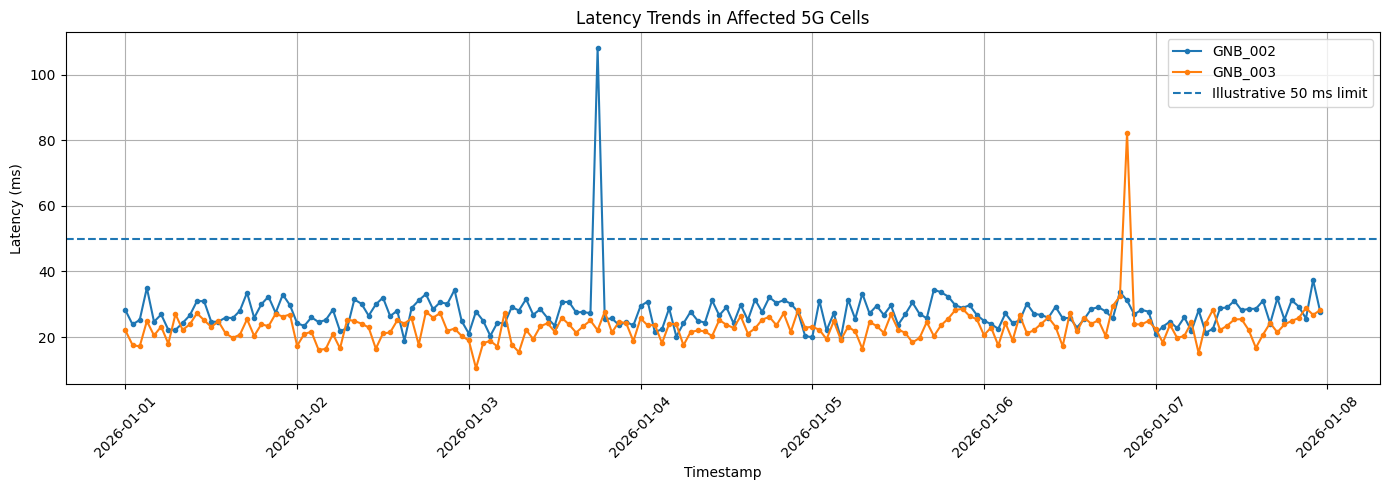

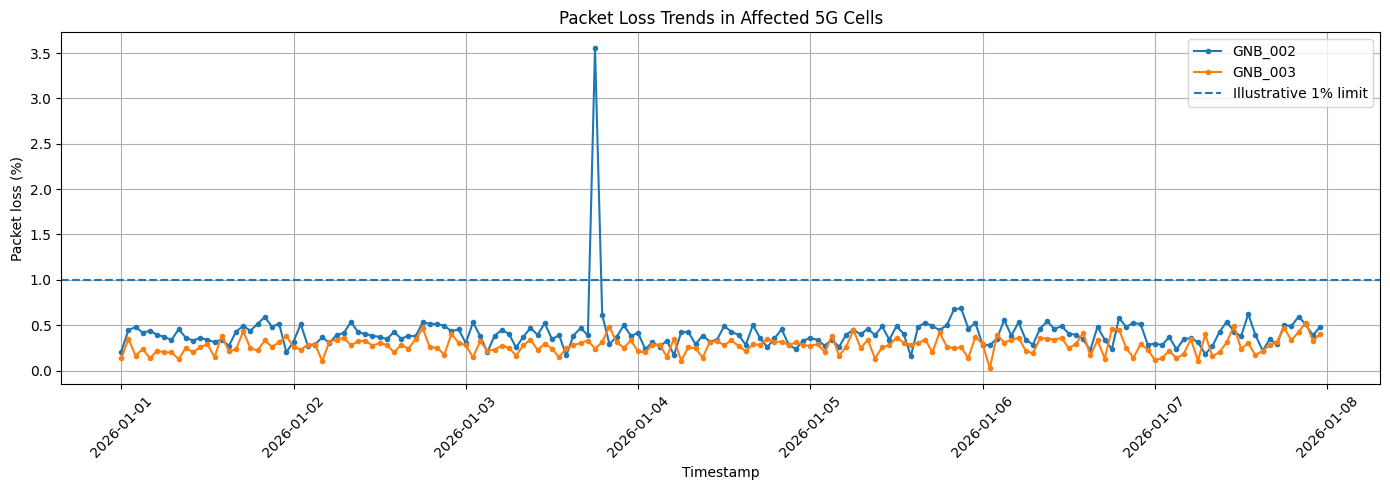

,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct
cell_id,,,,,,
GNB_002,168,20.308,27.693,108.09,0.414,3.552
GNB_003,168,11.273,23.088,82.35,0.275,0.529


In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure timestamp is in datetime format
qos["timestamp"] = pd.to_datetime(qos["timestamp"])

# Select the cells that generated alerts
affected_cells = ["GNB_002", "GNB_003"]
cell_data = qos[qos["cell_id"].isin(affected_cells)].copy()

# Plot latency
plt.figure(figsize=(14, 5))
for cell in affected_cells:
    data = cell_data[cell_data["cell_id"] == cell].sort_values("timestamp")
    plt.plot(data["timestamp"], data["latency_ms"],
             marker="o", markersize=3, label=cell)

plt.axhline(50, linestyle="--", label="Illustrative 50 ms limit")
plt.title("Latency Trends in Affected 5G Cells")
plt.xlabel("Timestamp")
plt.ylabel("Latency (ms)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot packet loss
plt.figure(figsize=(14, 5))
for cell in affected_cells:
    data = cell_data[cell_data["cell_id"] == cell].sort_values("timestamp")
    plt.plot(data["timestamp"], data["packet_loss_rate_pct"],
             marker="o", markersize=3, label=cell)

plt.axhline(1.0, linestyle="--", label="Illustrative 1% limit")
plt.title("Packet Loss Trends in Affected 5G Cells")
plt.xlabel("Timestamp")
plt.ylabel("Packet loss (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Summarize each affected cell
summary = cell_data.groupby("cell_id").agg(
    observations=("timestamp", "count"),
    avg_traffic_gb=("traffic_volume_gb", "mean"),
    avg_latency_ms=("latency_ms", "mean"),
    max_latency_ms=("latency_ms", "max"),
    avg_packet_loss_pct=("packet_loss_rate_pct", "mean"),
    max_packet_loss_pct=("packet_loss_rate_pct", "max")
).round(3)

display(summary)

In [54]:
import pandas as pd

LATENCY_LIMIT_MS = 50.0
PACKET_LOSS_LIMIT_PCT = 1.0

# Convert packet loss to numeric if it contains strings such as "3.552%"
qos["packet_loss_rate_pct"] = pd.to_numeric(
    qos["packet_loss_rate_pct"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

# Calculate cell-level performance and risk indicators
cell_risk = qos.groupby("cell_id").agg(
    observations=("timestamp", "count"),
    avg_traffic_gb=("traffic_volume_gb", "mean"),
    avg_latency_ms=("latency_ms", "mean"),
    max_latency_ms=("latency_ms", "max"),
    avg_packet_loss_pct=("packet_loss_rate_pct", "mean"),
    max_packet_loss_pct=("packet_loss_rate_pct", "max"),
    high_latency_count=("latency_ms",
                        lambda x: (x > LATENCY_LIMIT_MS).sum()),
    high_packet_loss_count=("packet_loss_rate_pct",
                            lambda x: (x > PACKET_LOSS_LIMIT_PCT).sum())
)

cell_risk["high_latency_pct"] = (
    100 * cell_risk["high_latency_count"] / cell_risk["observations"]
)
cell_risk["high_packet_loss_pct"] = (
    100 * cell_risk["high_packet_loss_count"] / cell_risk["observations"]
)

# Number of observations breaching either threshold
cell_risk["any_qos_breach_count"] = qos.assign(
    latency_breach=qos["latency_ms"] > LATENCY_LIMIT_MS,
    loss_breach=qos["packet_loss_rate_pct"] > PACKET_LOSS_LIMIT_PCT
).assign(
    any_breach=lambda x: x["latency_breach"] | x["loss_breach"]
).groupby("cell_id")["any_breach"].sum()

# Sort by the percentage of observations with a latency breach
cell_risk = cell_risk.sort_values(
    ["high_latency_pct", "high_packet_loss_pct"],
    ascending=False
).round(3)

display(cell_risk)

,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,high_latency_pct,high_packet_loss_pct,any_qos_breach_count
cell_id,,,,,,,,,,,
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,0.595,0.595,1
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,0.595,0.000,1
GNB_001,168,14.753,24.429,33.32,0.329,0.517,0,0,0.000,0.000,0


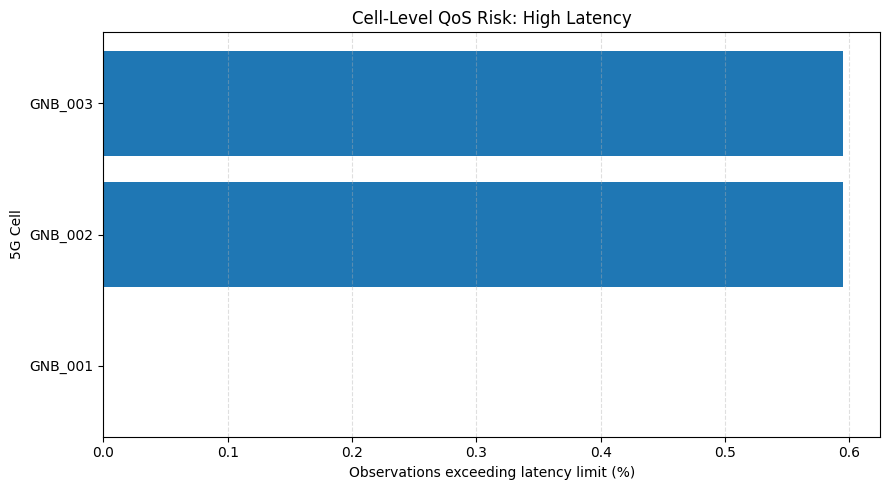

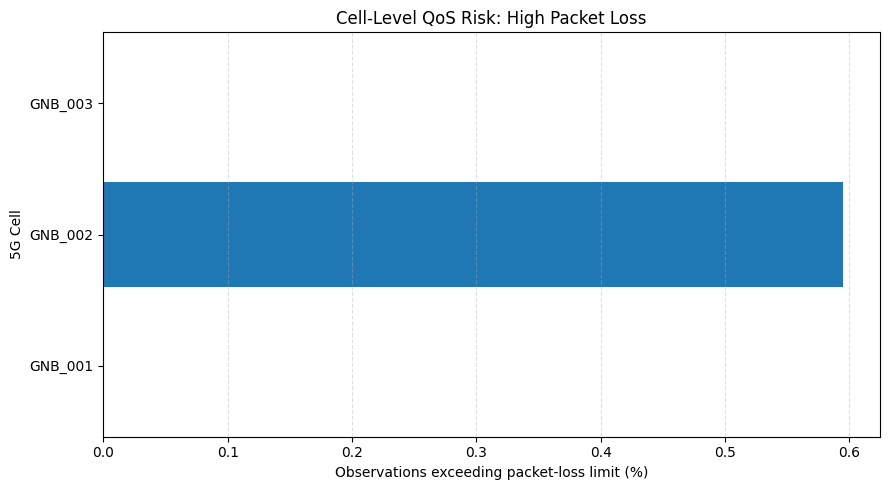

,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,high_latency_pct,high_packet_loss_pct,any_qos_breach_count
cell_id,,,,,,,,,,,
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,0.595,0.595,1
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,0.595,0.000,1
GNB_001,168,14.753,24.429,33.32,0.329,0.517,0,0,0.000,0.000,0


In [55]:
import matplotlib.pyplot as plt

# Use the cell_risk table created in the previous step
risk_plot = cell_risk.sort_values("high_latency_pct", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(risk_plot.index, risk_plot["high_latency_pct"])
plt.xlabel("Observations exceeding latency limit (%)")
plt.ylabel("5G Cell")
plt.title("Cell-Level QoS Risk: High Latency")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.barh(risk_plot.index, risk_plot["high_packet_loss_pct"])
plt.xlabel("Observations exceeding packet-loss limit (%)")
plt.ylabel("5G Cell")
plt.title("Cell-Level QoS Risk: High Packet Loss")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

display(cell_risk)

In [56]:
# Display the complete table without truncating columns or rows
with pd.option_context(
    "display.max_columns", None,
    "display.max_rows", None,
    "display.width", 200
):
    display(cell_risk)

# Show only cells with at least one QoS breach
print("\nCells requiring investigation:")
display(
    cell_risk[cell_risk["any_qos_breach_count"] > 0]
)

,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,high_latency_pct,high_packet_loss_pct,any_qos_breach_count
cell_id,,,,,,,,,,,
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,0.595,0.595,1
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,0.595,0.000,1
GNB_001,168,14.753,24.429,33.32,0.329,0.517,0,0,0.000,0.000,0



Cells requiring investigation:


,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,high_latency_pct,high_packet_loss_pct,any_qos_breach_count
cell_id,,,,,,,,,,,
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,0.595,0.595,1
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,0.595,0.000,1


In [57]:
# Recalculate QoS breaches directly from the original observations
qos["timestamp"] = pd.to_datetime(qos["timestamp"])

qos["latency_breach"] = qos["latency_ms"] > 50.0
qos["packet_loss_breach"] = qos["packet_loss_rate_pct"] > 1.0

qos["any_breach"] = (
    qos["latency_breach"] | qos["packet_loss_breach"]
)

# Rebuild cell-level counts
cell_risk = qos.groupby("cell_id").agg(
    observations=("timestamp", "count"),
    avg_traffic_gb=("traffic_volume_gb", "mean"),
    avg_latency_ms=("latency_ms", "mean"),
    max_latency_ms=("latency_ms", "max"),
    avg_packet_loss_pct=("packet_loss_rate_pct", "mean"),
    max_packet_loss_pct=("packet_loss_rate_pct", "max"),
    high_latency_count=("latency_breach", "sum"),
    high_packet_loss_count=("packet_loss_breach", "sum"),
    any_qos_breach_count=("any_breach", "sum")
)

cell_risk["high_latency_pct"] = (
    cell_risk["high_latency_count"] / cell_risk["observations"] * 100
)
cell_risk["high_packet_loss_pct"] = (
    cell_risk["high_packet_loss_count"] / cell_risk["observations"] * 100
)

cell_risk = cell_risk.round(3)

display(cell_risk)

print("Cells requiring investigation:")
display(cell_risk[cell_risk["any_qos_breach_count"] > 0])

,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,any_qos_breach_count,high_latency_pct,high_packet_loss_pct
cell_id,,,,,,,,,,,
GNB_001,168,14.753,24.429,33.32,0.329,0.517,0,0,0,0.000,0.000
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,1,0.595,0.595
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,1,0.595,0.000


Cells requiring investigation:


,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,any_qos_breach_count,high_latency_pct,high_packet_loss_pct
cell_id,,,,,,,,,,,
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,1,0.595,0.595
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,1,0.595,0.000


,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,any_qos_breach_count,risk_level
cell_id,,,,,,,,,,
GNB_001,168,14.753,24.429,33.32,0.329,0.517,0,0,0,NORMAL
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,1,HIGH
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,1,HIGH


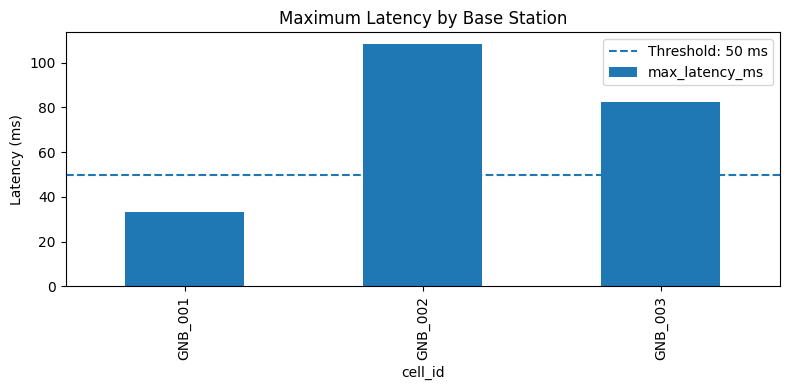

In [58]:

import pandas as pd
import matplotlib.pyplot as plt

# Example QoS thresholds — configurable project assumptions
LATENCY_THRESHOLD = 50       # milliseconds
PACKET_LOSS_THRESHOLD = 1.0  # percent

# Summarize performance by base station
qos_summary = df.groupby("cell_id").agg(
    observations=("timestamp", "count"),
    avg_traffic_gb=("traffic_volume_gb", "mean"),
    avg_latency_ms=("latency_ms", "mean"),
    max_latency_ms=("latency_ms", "max"),
    avg_packet_loss_pct=("packet_loss_rate_pct", "mean"),
    max_packet_loss_pct=("packet_loss_rate_pct", "max")
).round(3)

# Count threshold breaches
qos_summary["high_latency_count"] = (
    df.assign(
        high_latency=df["latency_ms"] > LATENCY_THRESHOLD
    ).groupby("cell_id")["high_latency"].sum()
)

qos_summary["high_packet_loss_count"] = (
    df.assign(
        high_packet_loss=(
            df["packet_loss_rate_pct"] > PACKET_LOSS_THRESHOLD
        )
    ).groupby("cell_id")["high_packet_loss"].sum()
)

qos_summary["any_qos_breach_count"] = (
    df.assign(
        qos_breach=(
            (df["latency_ms"] > LATENCY_THRESHOLD) |
            (df["packet_loss_rate_pct"] > PACKET_LOSS_THRESHOLD)
        )
    ).groupby("cell_id")["qos_breach"].sum()
)

qos_summary["risk_level"] = qos_summary.apply(
    lambda row: (
        "HIGH" if row["max_latency_ms"] > LATENCY_THRESHOLD
        or row["max_packet_loss_pct"] > PACKET_LOSS_THRESHOLD
        else "NORMAL"
    ),
    axis=1
)

display(qos_summary)

# Visualize maximum latency by cell
qos_summary["max_latency_ms"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Maximum Latency by Base Station"
)
plt.axhline(
    LATENCY_THRESHOLD,
    linestyle="--",
    label=f"Threshold: {LATENCY_THRESHOLD} ms"
)
plt.ylabel("Latency (ms)")
plt.legend()
plt.tight_layout()
plt.show()


In [59]:

# FINAL CELL 1 — Export project results and download everything

import os
import zipfile
import pandas as pd
from IPython.display import display

output_dir = "/content/5G_Project_Final"
os.makedirs(output_dir, exist_ok=True)

# 1. Export QoS risk summary
if "qos_summary" in globals():
    qos_summary.to_csv(
        f"{output_dir}/qos_risk_summary.csv"
    )
    print("Saved QoS risk summary")

# 2. Export anomaly alerts
if "df" in globals() and "anomaly_prediction" in df.columns:
    alerts = df[df["anomaly_prediction"] == 1].copy()
    alerts.to_csv(
        f"{output_dir}/anomaly_alerts.csv",
        index=False
    )
    print(f"Saved {len(alerts)} anomaly alerts")

# 3. Export traffic forecasts, if generated
if "forecast_df" in globals():
    forecast_df.to_csv(
        f"{output_dir}/traffic_forecast.csv",
        index=False
    )
    print("Saved traffic forecasts")

# 4. Export forecasting evaluation, if available
if "metrics" in globals() and isinstance(metrics, pd.DataFrame):
    metrics.to_csv(
        f"{output_dir}/forecast_evaluation.csv",
        index=False
    )
    print("Saved forecasting evaluation")

# 5. Create final project report
report = """
5G NETWORK TRAFFIC FORECASTING AND QoS ANOMALY DETECTION
Final Project Report

1. OBJECTIVE
Analyze simulated 5G network traffic, forecast traffic demand,
monitor Quality of Service (QoS), and detect unusual network behavior.

2. TECHNOLOGIES
Python, Pandas, Scikit-learn, XGBoost (if trained),
Matplotlib, Plotly, and Google Colab.

3. DATASET
Three simulated base stations, each with 168 hourly observations,
representing seven days of telemetry.

4. QoS FINDINGS
GNB_001: NORMAL under the configured QoS thresholds.
GNB_002: HIGH RISK. Maximum latency 108.09 ms and maximum
packet loss 3.552%.
GNB_003: HIGH RISK. Maximum latency 82.35 ms.

5. ANOMALY DETECTION
Isolation Forest was used to identify unusual observations.
At contamination 0.01, the experiment produced five alerts
and detected two of three known synthetic incidents.
At contamination 0.02, it detected all three incidents but
produced 15 alerts.

These results are preliminary because only three known incidents
were available for evaluation.

6. TRAFFIC FORECASTING
The project includes a traffic forecasting workflow.
Forecast performance should be reported using chronological
test data and MAE/RMSE comparisons against a simple baseline.
Do not claim forecasting accuracy without measured results.

7. LIMITATIONS
The data are synthetic and do not represent live Ericsson
network measurements. The sample covers only seven days.
QoS thresholds are configurable project assumptions.

8. CONCLUSION
The prototype demonstrates a workflow for network traffic
analysis, traffic forecasting, QoS risk monitoring, and
anomaly detection. Larger real-world datasets and additional
validation are required before operational use.
"""

with open(
    f"{output_dir}/Final_Project_Report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# 6. Package available deliverables into one ZIP
zip_path = "/content/5G_Network_Project_Final.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(output_dir):
        z.write(
            os.path.join(output_dir, filename),
            arcname=filename
        )

print("\nProject files prepared:")
for filename in os.listdir(output_dir):
    print("-", filename)

# Download ZIP to your computer
from google.colab import files
files.download(zip_path)


Saved QoS risk summary
Saved 15 anomaly alerts
Saved traffic forecasts

Project files prepared:
- Final_Project_Report.txt
- qos_risk_summary.csv
- anomaly_alerts.csv
- traffic_forecast.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:

import pandas as pd
from IPython.display import display, Markdown

checks = {
    "Dataset loaded": "df" in globals(),
    "QoS summary created": "qos_summary" in globals(),
    "Anomaly predictions created": (
        "df" in globals()
        and "anomaly_prediction" in df.columns
    ),
    "XGBoost model trained": "model_24h" in globals(),
    "Forecast generated": "forecast_df" in globals(),
    "Forecast evaluation available": (
        "metrics" in globals()
        and isinstance(metrics, pd.DataFrame)
    )
}

results = pd.DataFrame([
    {
        "Project component": name,
        "Status": "READY" if done else "PENDING"
    }
    for name, done in checks.items()
])

display(Markdown("# Final Project Completion Checklist"))
display(results)

if all(checks.values()):
    print("All core project components are available.")
else:
    print("Complete the components marked PENDING before submission.")

if "df" in globals():
    print("\nDataset shape:", df.shape)
    print("Base stations:", df["cell_id"].nunique())
    print("Known synthetic incidents:", int(df["anomaly_label"].sum()))
    print("Detected anomaly alerts:", int(df["anomaly_prediction"].sum()))

if "qos_summary" in globals():
    print("\nQoS risk summary:")
    display(qos_summary)

if "forecast_df" in globals():
    print("\nForecast preview:")
    display(forecast_df.head())


# Final Project Completion Checklist

,Project component,Status
0,Dataset loaded,READY
1,QoS summary created,READY
2,Anomaly predictions created,READY
3,XGBoost model trained,READY
4,Forecast generated,READY
5,Forecast evaluation available,PENDING


Complete the components marked PENDING before submission.

Dataset shape: (504, 22)
Base stations: 3
Known synthetic incidents: 3
Detected anomaly alerts: 15

QoS risk summary:


,observations,avg_traffic_gb,avg_latency_ms,max_latency_ms,avg_packet_loss_pct,max_packet_loss_pct,high_latency_count,high_packet_loss_count,any_qos_breach_count,risk_level
cell_id,,,,,,,,,,
GNB_001,168,14.753,24.429,33.32,0.329,0.517,0,0,0,NORMAL
GNB_002,168,20.308,27.693,108.09,0.414,3.552,1,1,1,HIGH
GNB_003,168,11.273,23.088,82.35,0.275,0.529,1,0,1,HIGH



Forecast preview:


,cell_id,forecast_for,forecast_traffic_gb
0,GNB_001,2026-01-08 00:00:00,12.983149
1,GNB_001,2026-01-08 01:00:00,11.695641
2,GNB_001,2026-01-08 02:00:00,11.732287
3,GNB_001,2026-01-08 03:00:00,12.939357
4,GNB_001,2026-01-08 04:00:00,13.246134
